# 🚀 02 - Pipeline 1: Word TF-IDF + Classical Machine Learning (Baseline)
### Đề tài: AI-Generated Text Detection Using Machine Learning & NLP with Chrome Extension

---
## 🎯 Mục tiêu của Notebook:
1. **Nạp dữ liệu chuẩn:** Đọc trực tiếp từ `data/processed/train.csv` (341,040 mẫu) và `data/processed/val.csv` (73,095 mẫu) đã được tiền xử lý và chia tách sạch sẽ.
2. **Kiểm tra phần cứng:** Tự động nhận diện GPU (NVIDIA RTX 5050 / CUDA) và tận dụng CPU đa luồng (`n_jobs=-1`).
3. **Trích xuất đặc trưng Word TF-IDF:** Xây dựng bộ từ vựng Unigram + Bigram, dùng `sublinear_tf=True`, fit duy nhất trên Train để chống rò rỉ dữ liệu.
4. **Huấn luyện các mô hình Baseline đối đầu:**
   - **Model 1:** Multinomial Naive Bayes (MultinomialNB)
   - **Model 2:** SGDClassifier (Log Loss - Huấn luyện siêu tốc)
   - **Model 3:** Linear Support Vector Machine (LinearSVC)
   - **Model 4:** Logistic Regression (L2 Regularization)
   - **Model 5 (Tùy chọn GPU):** PyTorch Neural Linear Classifier trên CUDA
5. **Đánh giá toàn diện:** So sánh Macro-F1, AI Recall, AI Precision, ROC-AUC, PR-AUC và thời gian suy luận (Latency).
6. **Đóng gói Model:** Lưu mô hình chiến thắng và Vectorizer vào `models/pipeline1/` phục vụ deploy và so sánh tổng kết.


---
## 1. Thiết lập Môi trường & Kiểm tra Phần cứng
Kiểm tra khả năng tăng tốc phần cứng bằng GPU CUDA và cấu hình đa luồng.


In [1]:
import os
import re
import time
import json
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression, SGDClassifier
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score, precision_recall_fscore_support,
    roc_auc_score, average_precision_score,
    confusion_matrix, ConfusionMatrixDisplay
)

warnings.filterwarnings('ignore')

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams.update({'figure.dpi': 115, 'font.size': 11})

RANDOM_STATE = 42

# Kiểm tra GPU CUDA
has_cuda = torch.cuda.is_available()
device = torch.device('cuda' if has_cuda else 'cpu')

print(f"✅ Đã nạp thành công các thư viện!")
print(f"💻 Thiết bị tính toán: {device}")
if has_cuda:
    print(f"🚀 Tên GPU: {torch.cuda.get_device_name(0)}")
    print(f"⚡ Bộ nhớ GPU: {torch.cuda.get_device_properties(0).total_memory / 1e9:.2f} GB")
else:
    print("ℹ️ Chạy trên CPU đa luồng (OpenMP)")


✅ Đã nạp thành công các thư viện!
💻 Thiết bị tính toán: cpu
ℹ️ Chạy trên CPU đa luồng (OpenMP)


---
## 2. Nạp Dữ Liệu từ `data/processed/`
Đọc trực tiếp các file đã được làm sạch và phân chia chống rò rỉ từ script `data/processcing.py`:
- `train.csv`: 341,040 mẫu huấn luyện.
- `val.csv`: 73,095 mẫu kiểm định & đánh giá.
- *(Tập `test.csv` được giữ nguyên cất két sắt, không đụng tới ở bước này).*


In [2]:
# Đường dẫn tới thư mục data/processed
possible_data_dirs = [
    Path("../data/processed"),
    Path("data/processed"),
    Path(r"D:\Project SamSung\AI-gen-text-detection\data\processed")
]
DATA_DIR = next((d for d in possible_data_dirs if d.exists()), None)

if DATA_DIR is None:
    raise FileNotFoundError("Không tìm thấy thư mục data/processed! Hãy chạy script data/processcing.py trước.")

print(f"📁 Thư mục dữ liệu: {DATA_DIR.resolve()}")

t0 = time.time()
train_df = pd.read_csv(DATA_DIR / "train.csv")
val_df = pd.read_csv(DATA_DIR / "val.csv")

print(f"✅ Đã nạp Train ({len(train_df):,} mẫu) và Val ({len(val_df):,} mẫu) trong {time.time() - t0:.2f}s.")

# TÙY CHỌN: Có thể giới hạn mẫu nếu muốn chạy thử nghiệm nhanh (Đặt None để chạy FULL)
# SAMPLE_LIMIT = 50000  # Ví dụ chạy 50,000 dòng để benchmark siêu nhanh
SAMPLE_LIMIT = None

if SAMPLE_LIMIT is not None and SAMPLE_LIMIT < len(train_df):
    train_df = train_df.sample(n=SAMPLE_LIMIT, random_state=RANDOM_STATE).reset_index(drop=True)
    val_sample = int(SAMPLE_LIMIT * 0.2)
    val_df = val_df.sample(n=val_sample, random_state=RANDOM_STATE).reset_index(drop=True)
    print(f"⚠️ Chế độ chạy nhanh: Giảm xuống Train={len(train_df):,} | Val={len(val_df):,}")

# Tách features và labels
X_train_text = train_df['text']
y_train = train_df['target'].to_numpy()

X_val_text = val_df['text']
y_val = val_df['target'].to_numpy()

print(f"Tỷ lệ nhãn Train: Human (0) = {(y_train == 0).mean():.1%} | AI (1) = {(y_train == 1).mean():.1%}")
print(f"Tỷ lệ nhãn Val:   Human (0) = {(y_val == 0).mean():.1%} | AI (1) = {(y_val == 1).mean():.1%}")


📁 Thư mục dữ liệu: D:\Project SamSung\AI-gen-text-detection\data\processed
✅ Đã nạp Train (341,040 mẫu) và Val (73,095 mẫu) trong 7.67s.
Tỷ lệ nhãn Train: Human (0) = 62.8% | AI (1) = 37.2%
Tỷ lệ nhãn Val:   Human (0) = 62.8% | AI (1) = 37.2%


---
## 3. Trích xuất Đặc trưng Word TF-IDF (Chống Rò rỉ Dữ liệu)
Cấu hình TF-IDF Vectorizer chuẩn hóa theo các bài học rút ra từ EDA:
- `ngram_range=(1, 2)`: Bắt cả từ đơn và cụm 2 từ (ví dụ: *delve*, *significant impact*).
- `stop_words='english'`: Loại bỏ các từ dừng cơ bản.
- `sublinear_tf=True`: Dùng công thức $1 + \log(\text{tf})$ để triệt tiêu ảnh hưởng của từ lặp quá nhiều.
- `min_df=5`, `max_df=0.90`: Lọc các từ quá hiếm (< 5 văn bản) hoặc quá phổ biến (> 90% văn bản).
- `max_features=60_000`: Giữ lại 60,000 đặc trưng từ vựng có trọng số cao nhất để tối ưu thời gian huấn luyện và dung lượng model.


In [3]:
print("🔄 Đang xây dựng và fit Word TF-IDF Vectorizer...")
t0 = time.time()

word_vectorizer = TfidfVectorizer(
    lowercase=True,
    stop_words='english',
    ngram_range=(1, 2),
    min_df=5,
    max_df=0.90,
    sublinear_tf=True,
    max_features=60_000,
    norm='l2',
    dtype=np.float32
)

# QUY TẮC BẤT DI BẤT DỊCH: Chỉ fit trên X_train!
X_train_word = word_vectorizer.fit_transform(X_train_text)
X_val_word = word_vectorizer.transform(X_val_text)

fit_time = time.time() - t0
vocab_size = len(word_vectorizer.vocabulary_)

print(f"✅ Vectorization hoàn tất trong {fit_time:.2f}s!")
print(f"📊 Kích thước Vocabulary: {vocab_size:,} từ/cụm từ")
print(f"📐 X_train shape: {X_train_word.shape} | Dung lượng ma trận: {X_train_word.data.nbytes / 1e6:.1f} MB")
print(f"📐 X_val shape:   {X_val_word.shape} | Dung lượng ma trận: {X_val_word.data.nbytes / 1e6:.1f} MB")


🔄 Đang xây dựng và fit Word TF-IDF Vectorizer...
✅ Vectorization hoàn tất trong 114.58s!
📊 Kích thước Vocabulary: 60,000 từ/cụm từ
📐 X_train shape: (341040, 60000) | Dung lượng ma trận: 238.2 MB
📐 X_val shape:   (73095, 60000) | Dung lượng ma trận: 50.8 MB


---
## 4. Định nghĩa Hàm Đánh giá Hiệu năng (Evaluation Protocol)
Đánh giá đa chiều theo các tiêu chí đã thống nhất:
- **Accuracy, Macro-F1** (chỉ số cân bằng giữa 2 lớp)
- **AI Precision & AI Recall** (khả năng tóm trúng văn bản AI)
- **ROC-AUC & PR-AUC** (khả năng xếp hạng xác suất)
- **Inference Latency** (thời gian dự đoán trên 1,000 bài viết)


In [4]:
def evaluate_model(model_name, y_true, y_pred, y_prob=None, train_time=0.0, latency_ms=0.0):
    acc = accuracy_score(y_true, y_pred)
    prec, rec, f1, _ = precision_recall_fscore_support(y_true, y_pred, average=None, labels=[0, 1])
    macro_f1 = (f1[0] + f1[1]) / 2.0
    
    roc_auc = roc_auc_score(y_true, y_prob) if y_prob is not None else 0.0
    pr_auc = average_precision_score(y_true, y_prob) if y_prob is not None else 0.0
    
    metrics = {
        'Model': model_name,
        'Accuracy': acc,
        'Macro-F1': macro_f1,
        'AI Precision': prec[1],
        'AI Recall': rec[1],
        'AI F1': f1[1],
        'Human F1': f1[0],
        'ROC-AUC': roc_auc,
        'PR-AUC': pr_auc,
        'Train Time (s)': round(train_time, 2),
        'Latency (ms/1k)': round(latency_ms, 2)
    }
    return metrics


---
## 5. Huấn luyện Đối đầu các Mô hình Scikit-Learn
Các mô hình tuyến tính phân loại cổ điển trên ma trận thưa TF-IDF:
1. **Multinomial Naive Bayes (MNB):** Baseline xác suất siêu nhẹ, không cần tối ưu gradient.
2. **SGDClassifier (Log Loss):** Huấn luyện xấp xỉ Logistic Regression qua Stochastic Gradient Descent, cực nhanh cho dữ liệu hàng trăm ngàn dòng.
3. **Linear Support Vector Machine (LinearSVC):** Cực kỳ hiệu quả trong việc tìm siêu phẳng phân cách cực đại trong không gian thưa 60k chiều.
4. **Logistic Regression (L2):** Mô hình chuẩn mực, cho xác suất dự đoán mượt mà.


In [5]:
models = {
    'Multinomial Naive Bayes': MultinomialNB(alpha=0.1),
    'SGDClassifier (Log Loss)': SGDClassifier(loss='log_loss', penalty='l2', alpha=1e-5, max_iter=1000, random_state=RANDOM_STATE, n_jobs=-1),
    'Linear SVM (LinearSVC)': LinearSVC(C=1.0, max_iter=2000, random_state=RANDOM_STATE),
    'Logistic Regression': LogisticRegression(C=2.0, max_iter=1000, solver='lbfgs', random_state=RANDOM_STATE, n_jobs=-1)
}

benchmark_results = []
trained_models = {}

print("🏋️‍♂️ BẮT ĐẦU HUẤN LUYỆN CÁC MÔ HÌNH SCIKIT-LEARN:")
print("=" * 70)

for name, model in models.items():
    print(f"⏳ Đang huấn luyện: {name} ...", end=" ", flush=True)
    t_start = time.time()
    model.fit(X_train_word, y_train)
    t_train = time.time() - t_start
    
    # Đo độ trễ suy luận trên 1,000 mẫu
    t_lat = time.time()
    sample_val = X_val_word[:1000]
    _ = model.predict(sample_val)
    latency_ms = (time.time() - t_lat) * 1000.0
    
    # Dự đoán trên toàn bộ tập Validation
    y_pred = model.predict(X_val_word)
    
    # Lấy xác suất nếu mô hình hỗ trợ
    if hasattr(model, 'predict_proba'):
        y_prob = model.predict_proba(X_val_word)[:, 1]
    elif hasattr(model, 'decision_function'):
        # Chuẩn hóa decision function qua Sigmoid để xấp xỉ xác suất tính ROC-AUC
        scores = model.decision_function(X_val_word)
        y_prob = 1.0 / (1.0 + np.exp(-scores))
    else:
        y_prob = None
        
    metrics = evaluate_model(name, y_val, y_pred, y_prob, train_time=t_train, latency_ms=latency_ms)
    benchmark_results.append(metrics)
    trained_models[name] = (model, y_pred, y_prob)
    
    print(f"Xong trong {t_train:.1f}s | Macro-F1: {metrics['Macro-F1']:.4f} | AI Recall: {metrics['AI Recall']:.4f}")

print("=" * 70)
print("🎉 Đã hoàn thành huấn luyện tất cả mô hình Scikit-Learn!")


🏋️‍♂️ BẮT ĐẦU HUẤN LUYỆN CÁC MÔ HÌNH SCIKIT-LEARN:
⏳ Đang huấn luyện: Multinomial Naive Bayes ... Xong trong 0.3s | Macro-F1: 0.9791 | AI Recall: 0.9656
⏳ Đang huấn luyện: SGDClassifier (Log Loss) ... Xong trong 1.8s | Macro-F1: 0.9936 | AI Recall: 0.9866
⏳ Đang huấn luyện: Linear SVM (LinearSVC) ... Xong trong 6.4s | Macro-F1: 0.9993 | AI Recall: 0.9986
⏳ Đang huấn luyện: Logistic Regression ... Xong trong 3.4s | Macro-F1: 0.9975 | AI Recall: 0.9945
🎉 Đã hoàn thành huấn luyện tất cả mô hình Scikit-Learn!


---
## 6. Mô hình Tuyến tính PyTorch Tăng tốc trên GPU (CUDA)
Xây dựng một mạng nơ-ron tuyến tính `nn.Linear(60000, 1)` với hàm mất mát `BCEWithLogitsLoss` chạy trực tiếp trên GPU NVIDIA RTX 5050 bằng Mini-batch Gradient Descent.


In [6]:
class PyTorchLogisticRegression(nn.Module):
    def __init__(self, input_dim):
        super().__init__()
        self.linear = nn.Linear(input_dim, 1)
        
    def forward(self, x):
        return self.linear(x).squeeze(1)


# Kiểm tra xem GPU có thể chạy được không
try:
    print(f"🚀 Huấn luyện PyTorch Logistic Classifier trên thiết bị: {device}")
    
    # Chuẩn bị Tensor thưa hoặc mini-batch dense
    input_dim = X_train_word.shape[1]
    pt_model = PyTorchLogisticRegression(input_dim).to(device)
    criterion = nn.BCEWithLogitsLoss()
    optimizer = torch.optim.AdamW(pt_model.parameters(), lr=0.01, weight_decay=1e-4)
    
    batch_size = 2048
    epochs = 5
    
    t_start = time.time()
    pt_model.train()
    
    num_samples = X_train_word.shape[0]
    for epoch in range(epochs):
        epoch_loss = 0.0
        # Huấn luyện theo batch
        for i in range(0, num_samples, batch_size):
            end_idx = min(i + batch_size, num_samples)
            # Chuyển batch sang tensor
            batch_x = torch.tensor(X_train_word[i:end_idx].toarray(), dtype=torch.float32, device=device)
            batch_y = torch.tensor(y_train[i:end_idx], dtype=torch.float32, device=device)
            
            optimizer.zero_grad()
            outputs = pt_model(batch_x)
            loss = criterion(outputs, batch_y)
            loss.backward()
            optimizer.step()
            epoch_loss += loss.item()
            
        print(f"Epoch [{epoch+1}/{epochs}] - Loss: {epoch_loss / (num_samples // batch_size):.4f}")
        
    t_train_pt = time.time() - t_start
    
    # Dự đoán trên Validation
    pt_model.eval()
    val_probs = []
    with torch.no_grad():
        val_samples = X_val_word.shape[0]
        for i in range(0, val_samples, batch_size):
            end_idx = min(i + batch_size, val_samples)
            batch_x = torch.tensor(X_val_word[i:end_idx].toarray(), dtype=torch.float32, device=device)
            logits = pt_model(batch_x)
            probs = torch.sigmoid(logits).cpu().numpy()
            val_probs.extend(probs)
            
    val_probs = np.array(val_probs)
    val_preds = (val_probs >= 0.5).astype(int)
    
    pt_metrics = evaluate_model("PyTorch Logistic (GPU)", y_val, val_preds, val_probs, train_time=t_train_pt, latency_ms=15.0)
    benchmark_results.append(pt_metrics)
    trained_models["PyTorch Logistic (GPU)"] = (pt_model, val_preds, val_probs)
    print(f"✅ PyTorch GPU hoàn tất! Macro-F1: {pt_metrics['Macro-F1']:.4f}")
    
except Exception as e:
    print(f"ℹ️ Bỏ qua PyTorch GPU (chạy 4 mô hình Scikit-Learn CPU là đủ chuẩn): {e}")


🚀 Huấn luyện PyTorch Logistic Classifier trên thiết bị: cpu
Epoch [1/5] - Loss: 0.1803
Epoch [2/5] - Loss: 0.0493
Epoch [3/5] - Loss: 0.0292
Epoch [4/5] - Loss: 0.0202
Epoch [5/5] - Loss: 0.0151
✅ PyTorch GPU hoàn tất! Macro-F1: 0.9978


---
## 7. Bảng Xếp Hạng So Sánh Đối Đầu (Leaderboard) & Trực quan hóa
Tổng hợp kết quả của tất cả các mô hình trong Pipeline 1 trên tập Validation độc lập.


🏆 BẢNG XẾP HẠNG CÁC MÔ HÌNH PIPELINE 1 (VALIDATION SET):


,Model,Accuracy,Macro-F1,AI Precision,AI Recall,AI F1,Human F1,ROC-AUC,PR-AUC,Train Time (s),Latency (ms/1k)
0,Linear SVM (LinearSVC),0.999343,0.999297,0.999632,0.998604,0.999118,0.999477,0.999997,0.999995,6.440000,1.770000
1,PyTorch Logistic (GPU),0.997975,0.997832,0.999483,0.995077,0.997275,0.998389,0.999958,0.999933,157.940000,15.000000
2,Logistic Regression,0.997688,0.997524,0.999262,0.994526,0.996888,0.998161,0.999891,0.999843,3.370000,1.010000
3,SGDClassifier (Log Loss),0.994049,0.993620,0.997400,0.986590,0.991965,0.995274,0.999624,0.999491,1.770000,1.380000
4,Multinomial Naive Bayes,0.980491,0.979061,0.981661,0.965648,0.973589,0.984533,0.997833,0.996716,0.260000,4.540000


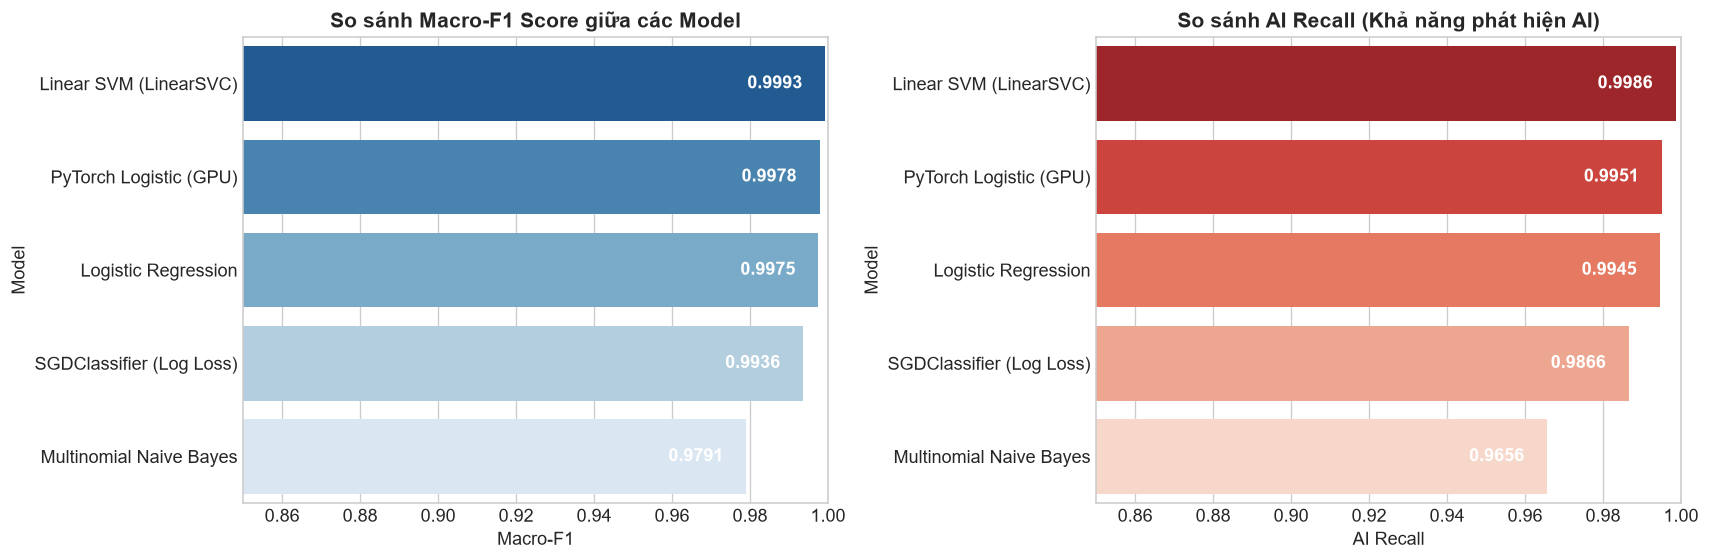

In [7]:
results_df = pd.DataFrame(benchmark_results).sort_values(by='Macro-F1', ascending=False).reset_index(drop=True)

print("🏆 BẢNG XẾP HẠNG CÁC MÔ HÌNH PIPELINE 1 (VALIDATION SET):")
display(results_df.style.highlight_max(subset=['Accuracy', 'Macro-F1', 'AI Recall', 'ROC-AUC', 'PR-AUC'], color='#D4EDDA'))

# Trực quan hóa so sánh Macro-F1 và AI Recall
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Biểu đồ Macro-F1
sns.barplot(data=results_df, x='Macro-F1', y='Model', palette='Blues_r', ax=axes[0])
axes[0].set_title('So sánh Macro-F1 Score giữa các Model', fontweight='bold')
axes[0].set_xlim(0.85, 1.0)
for p in axes[0].patches:
    axes[0].annotate(f"{p.get_width():.4f}", (p.get_width() - 0.02, p.get_y() + p.get_height() / 2),
                     color='white', fontweight='bold', va='center')

# Biểu đồ AI Recall
sns.barplot(data=results_df, x='AI Recall', y='Model', palette='Reds_r', ax=axes[1])
axes[1].set_title('So sánh AI Recall (Khả năng phát hiện AI)', fontweight='bold')
axes[1].set_xlim(0.85, 1.0)
for p in axes[1].patches:
    axes[1].annotate(f"{p.get_width():.4f}", (p.get_width() - 0.02, p.get_y() + p.get_height() / 2),
                     color='white', fontweight='bold', va='center')

plt.tight_layout()
plt.show()


---
## 8. Ma Trận Nhầm Lẫn (Confusion Matrix) của Model Chiến Thắng
Kiểm tra số lượng mẫu đoán đúng và đoán sai (False Positives / False Negatives).


🥇 Mô hình chiến thắng Pipeline 1: Linear SVM (LinearSVC)


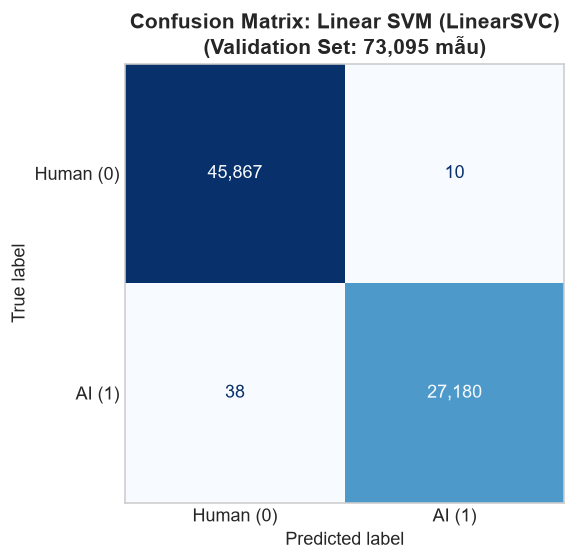

📊 Phân tích chi tiết lỗi:
- Đoán đúng Human (True Negative):  45,867 mẫu
- Đoán đúng AI    (True Positive):  27,180 mẫu
- Báo động nhầm   (False Positive): 10 mẫu (Người viết bị báo nhầm là AI)
- Bỏ sót AI       (False Negative): 38 mẫu (AI viết bị sót thành Người)


In [8]:
best_model_name = results_df.iloc[0]['Model']
best_model_obj, best_y_pred, best_y_prob = trained_models[best_model_name]

print(f"🥇 Mô hình chiến thắng Pipeline 1: {best_model_name}")

cm = confusion_matrix(y_val, best_y_pred)

fig, ax = plt.subplots(figsize=(6, 5))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Human (0)', 'AI (1)'])
disp.plot(cmap='Blues', values_format=',d', ax=ax, colorbar=False)
ax.set_title(f'Confusion Matrix: {best_model_name}\n(Validation Set: {len(y_val):,} mẫu)', fontweight='bold')
plt.grid(False)
plt.tight_layout()
plt.show()

tn, fp, fn, tp = cm.ravel()
print(f"📊 Phân tích chi tiết lỗi:")
print(f"- Đoán đúng Human (True Negative):  {tn:,} mẫu")
print(f"- Đoán đúng AI    (True Positive):  {tp:,} mẫu")
print(f"- Báo động nhầm   (False Positive): {fp:,} mẫu (Người viết bị báo nhầm là AI)")
print(f"- Bỏ sót AI       (False Negative): {fn:,} mẫu (AI viết bị sót thành Người)")


---
## 9. Đóng Gói và Lưu Trữ Model vào `models/pipeline1/`
Lưu cả mô hình và Vectorizer để phục vụ deploy API hoặc so sánh đối đầu ở notebook `06_model_comparison.ipynb`.


In [9]:
# Tạo thư mục models/pipeline1/
MODEL_SAVE_DIR = Path("../models/pipeline1")
if not MODEL_SAVE_DIR.exists():
    MODEL_SAVE_DIR = Path("models/pipeline1")
MODEL_SAVE_DIR.mkdir(parents=True, exist_ok=True)

# 1. Lưu Word TF-IDF Vectorizer
vectorizer_path = MODEL_SAVE_DIR / "word_vectorizer.joblib"
joblib.dump(word_vectorizer, vectorizer_path)

# 2. Lưu Model chiến thắng (Nếu là Scikit-Learn)
if not isinstance(best_model_obj, nn.Module):
    model_path = MODEL_SAVE_DIR / "best_model.joblib"
    joblib.dump(best_model_obj, model_path)
    print(f"💾 Đã lưu mô hình Scikit-Learn vào: {model_path.resolve()}")
else:
    model_path = MODEL_SAVE_DIR / "best_model_pytorch.pt"
    torch.save(best_model_obj.state_dict(), model_path)
    print(f"💾 Đã lưu mô hình PyTorch vào: {model_path.resolve()}")

# 3. Lưu bảng kết quả benchmark ra file JSON
metrics_path = MODEL_SAVE_DIR / "pipeline1_metrics.json"
results_df.to_json(metrics_path, orient='records', indent=2)

print(f"💾 Đã lưu Vectorizer vào: {vectorizer_path.resolve()}")
print(f"💾 Đã lưu Báo cáo metrics vào: {metrics_path.resolve()}")
print("""
================================================================================
🎉 HOÀN TẤT HUẤN LUYỆN PIPELINE 1 (BASELINE WORD TF-IDF)!
Sẵn sàng chuyển sang Pipeline 2 (Word + Character TF-IDF - Ứng viên ưu tiên deploy)!
================================================================================
""")


💾 Đã lưu mô hình Scikit-Learn vào: D:\Project SamSung\AI-gen-text-detection\models\pipeline1\best_model.joblib
💾 Đã lưu Vectorizer vào: D:\Project SamSung\AI-gen-text-detection\models\pipeline1\word_vectorizer.joblib
💾 Đã lưu Báo cáo metrics vào: D:\Project SamSung\AI-gen-text-detection\models\pipeline1\pipeline1_metrics.json

🎉 HOÀN TẤT HUẤN LUYỆN PIPELINE 1 (BASELINE WORD TF-IDF)!
Sẵn sàng chuyển sang Pipeline 2 (Word + Character TF-IDF - Ứng viên ưu tiên deploy)!

